# Interactive Kinetic Theory — Notebook 02
## Binet's Equation and Rutherford's Formula

**Course:** Kinetic Theory of Plasmas

This notebook accompanies **Problem 2 (Binet's equation and Rutherford's formula for
Coulomb interactions)**. The derivations are left to you; here you can *play* with a
binary collision: choose the pair, the interaction potential, the incoming speed and
the impact parameter, and see how the trajectory, the deflection angle $\chi(b)$ and
the effective potential respond.

### Learning objectives
After working through this notebook you should be able to:

1. reduce a two-body collision to the motion of a particle of reduced mass $\mu$ in a
   central potential $U(r)$;
2. use conservation of energy and angular momentum to locate the turning point $r_0$
   and compute the swept angle $\Theta$;
3. explain why the asymptotic deflection is $\chi=\pi-2\Theta$ and read it from a
   trajectory;
4. derive and test the hard-sphere and Rutherford formulas for $\chi(b)$;
5. recognise how the deflection curve changes with the exponent $n$ of an
   inverse-power-law potential.


---
## The problem

The dynamics of a binary collision can be reduced to the motion of a particle of reduced
mass $\mu$ subject to a central force $\vec F(r)$, where $r$ is the modulus of the
relative distance between the particles. The sketch below shows the geometry of the
collision. We assume that the particle approaches the force center from infinity with
velocity $\vec g$, where the force vanishes. The force derives from a potential, i.e.
$\vec F=-\nabla U(r)$. In the figure, $r$ and $\theta$ are polar coordinates.

<p align="center">
  <img src="figures/binet_geometry.png" width="560">
</p>

<p align="center"><em>Collision geometry: incoming asymptote at impact parameter $b$,
closest approach $r_0$, swept angle $\Theta$ and asymptotic deflection $\chi$.</em></p>

The goal is to study the asymptotic deflection angle $\chi$ as a function of the impact
parameter $b$, the velocity $g$ and the potential $U(r)$.

### Binet's equation

**1.** Write the equation of motion and derive from it the conservation of energy and
angular momentum.

**(a)** Prove that the previous conservation laws in polar coordinates read:
$$
\frac{1}{2}\mu\left(\dot r^2+r^2\dot\theta^2\right)+U=\frac{1}{2}\mu g^2,
\qquad
r^2\dot\theta=bg.
$$

**(b)** Does the trajectory always remain in a plane?

**2.** Prove that the radial equation can be written as:
$$
\left(\frac{\dot r}{g}\right)^2+\frac{2U(r)}{\mu g^2}+\left(\frac{b}{r}\right)^2=1.
$$

**3.** Equation for the angle $\theta$.

**(a)** Using the previous expressions, show that
$$
\frac{d\theta}{dr}
=\frac{b}{r^2}\frac{1}{\sqrt{1-\dfrac{2U(r)}{\mu g^2}-\left(\dfrac{b}{r}\right)^2}}.
$$

**(b)** What is the condition for the distance of closest approach?

**(c)** Show that the asymptotic deflection angle is $\chi=\pi-2\Theta$. Why?

**(d)** Prove that the azimuthal angle at closest approach is
$$
\Theta=\int_{r_0}^{\infty}\frac{b}{r^2}
\frac{1}{\sqrt{1-\dfrac{2U(r)}{\mu g^2}-\left(\dfrac{b}{r}\right)^2}}\,dr
\qquad\text{with}\qquad
r_0^2-\frac{2r_0^2U(r_0)}{\mu g^2}-b^2=0.
$$

> **Remark — Binet's equation.** Eliminating the time in favour of $u=1/r$ gives
> $$u''+u=-\frac{\mu F(1/u)}{L^2u^2},\qquad L=\mu bg,$$
> which is the equation usually called *Binet's equation*. The integral for $\Theta$ in
> item 3(d) is its first integral.


---
## 0. Setup: constants, species and helper functions

The code uses **SI units internally** (lengths in m, energies in J, velocities in m/s).
The figures convert to **nm** and **eV**, and the dashboard accepts the speed in
**km/s**. For each pair we compute the reduced mass
$$
\mu=\frac{m_1m_2}{m_1+m_2},
$$
and, for Coulomb, the charge product $k=Z_1Z_2e^2/(4\pi\varepsilon_0)$.

The characteristic length used in the normalized panels is
$$
\ell=
\begin{cases}
a, & \text{hard sphere},\\[2pt]
\left(\dfrac{|k|}{\mu g^2}\right)^{1/n}, & U=k/r^n.
\end{cases}
$$
For $n=1$ this is the impact parameter $b_{90}=|k|/(\mu g^2)$ that gives a $90^\circ$
deflection. Run the cells below once; afterwards the sliders drive every plot.


In [1]:
# Core scientific stack
import numpy as np
from scipy import constants as const
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Arc
import ipywidgets as widgets
from IPython.display import display
from io import BytesIO

# Render figures inside the notebook
%matplotlib inline

# Nicer default figure style
plt.rcParams.update({
    "figure.figsize": (12, 4.6),
    "font.size": 12,
    "axes.grid": True,
    "grid.alpha": 0.3,
})


In [2]:
q_e = const.e
m_e = const.m_e
u = const.u
eps0 = const.epsilon_0

SPECIES = {
    "e":   (m_e, -1),
    "H":   (1.00784 * u, 0),
    "H+":  (1.007276 * u, +1),
    "He":  (4.002602 * u, 0),
    "He+": (4.002602 * u - m_e, +1),
    "Ar":  (39.948 * u, 0),
    "Ar+": (39.948 * u - m_e, +1),
    "Xe":  (131.293 * u, 0),
    "Xe+": (131.293 * u - m_e, +1),
}

COL_TRAJ = "#1f4e9c"
COL_R0 = "#b23a3a"
COL_ANA = "#d17a22"

for _name, (_mass, _Z) in SPECIES.items():
    print(f"{_name:4s}  m = {_mass:.4e} kg   Z = {_Z:+d}")


e     m = 9.1094e-31 kg   Z = -1
H     m = 1.6736e-27 kg   Z = +0
H+    m = 1.6726e-27 kg   Z = +1
He    m = 6.6465e-27 kg   Z = +0
He+   m = 6.6456e-27 kg   Z = +1
Ar    m = 6.6335e-26 kg   Z = +0
Ar+   m = 6.6334e-26 kg   Z = +1
Xe    m = 2.1802e-25 kg   Z = +0
Xe+   m = 2.1802e-25 kg   Z = +1


In [3]:
def pair_properties(s1, s2):
    m1, z1 = SPECIES[s1]
    m2, z2 = SPECIES[s2]
    mu = m1 * m2 / (m1 + m2)
    k_coulomb = z1 * z2 * q_e**2 / (4 * np.pi * eps0)
    return mu, k_coulomb


def pair_sign(proj, targ):
    """Return +1 for like/neutral pairs and -1 for opposite charges."""
    z1 = SPECIES[proj][1]
    z2 = SPECIES[targ][1]
    return -1.0 if z1 * z2 < 0 else 1.0


def length_scale(k, mu, g, n):
    if k == 0:
        return 1e-9
    return (abs(k) / (mu * g * g)) ** (1.0 / n)


def U_power(r, k, n):
    return k / r**n


def f_radial(r, b, g, mu, k, n):
    return 1.0 - 2.0 * U_power(r, k, n) / (mu * g * g) - (b / r) ** 2


In [4]:
def turning_point_power(b, g, mu, k, n):
    if b == 0:
        return 0.0
    ell = length_scale(k, mu, g, n)
    xs = np.logspace(-8, 8, 6000)
    fx = f_radial(ell * xs, b, g, mu, k, n)
    roots = []
    for i in range(len(xs) - 1):
        if fx[i] * fx[i + 1] < 0:
            try:
                x = brentq(lambda xx: f_radial(ell * xx, b, g, mu, k, n),
                           xs[i], xs[i + 1], xtol=1e-14, rtol=1e-14)
                roots.append(ell * x)
            except ValueError:
                pass
    if not roots:
        return None
    return max(roots)


def theta_orbit_power(b, g, mu, k, n, r0):
    """Theta = integral_{r0}^{inf} ... using u = b/r = u0 sin(phi).

    The integrand is finite at phi = pi/2.  We integrate up to
    pi/2 - delta and add the last sliver with its analytic limit,
    which avoids the 0/0 and the cancellation of f near r0.
    """
    if r0 is None or r0 == 0 or b == 0:
        return np.nan
    u0 = b / r0
    fprime = (2 * n * k / (mu * g * g * r0 ** (n + 1))
              + 2 * b * b / r0 ** 3)
    if fprime <= 0:
        return np.nan
    limit = u0 / np.sqrt(0.5 * fprime * r0)
    delta = 1e-3

    def integrand(phi):
        s = np.sin(phi)
        if s <= 0:
            return u0
        r = b / (u0 * s)
        f = f_radial(r, b, g, mu, k, n)
        return u0 * np.cos(phi) / np.sqrt(max(f, 1e-300))

    val, _ = quad(integrand, 0, np.pi / 2 - delta, limit=200)
    return val + limit * delta


def chi_power(b, g, mu, k, n):
    r0 = turning_point_power(b, g, mu, k, n)
    if r0 is None:
        return np.nan, None
    return np.pi - 2 * theta_orbit_power(b, g, mu, k, n, r0), r0


def theta_hard(b, a):
    b = np.asarray(b, dtype=float)
    return np.where(b >= a, np.pi / 2, np.arcsin(np.clip(b / a, 0.0, 1.0)))


def chi_hard(b, a):
    return np.pi - 2 * theta_hard(b, a)


In [5]:
def _initial_velocity(b, g, mu, k, n, R):
    x0 = -np.sqrt(max(R * R - b * b, 0.0))
    y0 = b
    rhat = np.array([x0, y0]) / R
    that = np.array([y0, -x0]) / R
    U_R = U_power(R, k, n)
    vr2 = g * g - 2.0 * U_R / mu - (b * g / R) ** 2
    vr = -np.sqrt(max(vr2, 0.0))
    vt = b * g / R
    v = vr * rhat + vt * that
    return x0, y0, v[0], v[1]


def trajectory_power(b, g, mu, k, n, R_factor=80):
    ell = length_scale(k, mu, g, n)
    R = R_factor * max(ell, b)
    # Start just inside R so that the exit event is not exactly zero at t = 0
    # (solve_ivp may otherwise report a spurious event at the initial point).
    R_start = R * (1.0 - 1e-9)
    x0, y0, vx0, vy0 = _initial_velocity(b, g, mu, k, n, R_start)

    def rhs(t, s):
        x, y, vx, vy = s
        r = np.hypot(x, y)
        fac = n * k / (mu * r ** (n + 2))
        return [vx, vy, fac * x, fac * y]

    def ev_exit(t, s):
        return np.hypot(s[0], s[1]) - R

    ev_exit.terminal = True
    ev_exit.direction = 1

    def ev_capture(t, s):
        return np.hypot(s[0], s[1]) - 1e-4 * ell

    ev_capture.terminal = True
    ev_capture.direction = -1

    sol = solve_ivp(rhs, [0, 200 * R / g], [x0, y0, vx0, vy0],
                    events=[ev_exit, ev_capture], rtol=1e-9, atol=1e-12,
                    max_step=(R / g) / 500.0)
    return sol, R


def trajectory_hard(b, a, g, R_factor=80):
    R = R_factor * max(a, b)
    if b >= a:
        return (np.array([-R, R]), np.array([b, b]), b, 0.0,
                np.array([1.0, 0.0]))
    xc = -np.sqrt(a * a - b * b)
    yc = b
    nvec = np.array([xc, yc]) / a
    vin = np.array([g, 0.0])
    vout = vin - 2 * np.dot(vin, nvec) * nvec
    A = np.dot(vout, vout)
    B = 2 * np.dot(np.array([xc, yc]), vout)
    C = xc * xc + yc * yc - R * R
    t = (-B + np.sqrt(B * B - 4 * A * C)) / (2 * A)
    x2 = xc + vout[0] * t
    y2 = yc + vout[1] * t
    x = np.array([-R, xc, x2])
    y = np.array([b, yc, y2])
    chi = np.arctan2(vin[0] * vout[1] - vin[1] * vout[0], np.dot(vin, vout))
    return x, y, a, chi, vout / np.linalg.norm(vout)


In [6]:
def derived(proj, targ, potential, g_km, b_over_ell, a_nm, n,
            custom, k_custom):
    mu, k_coul = pair_properties(proj, targ)
    g = g_km * 1e3
    a = a_nm * 1e-9
    hard = potential == "Hard sphere"
    if hard:
        ell = a
        b = b_over_ell * ell
        k = 0.0
        n_eff = 1
    else:
        n_eff = n
        if n == 1 and not custom:
            k = k_coul
        else:
            k = pair_sign(proj, targ) * k_custom * q_e * (1e-9) ** n
        ell = length_scale(k, mu, g, n)
        b = b_over_ell * ell
    return dict(mu=mu, k=k, g=g, a=a, b=b, ell=ell, n=n_eff, hard=hard)


In [7]:
def _draw_panel(ax, x, y, d, r0, chi, theta0, r0pt, hard, scale, unit,
                capture=False, normalized=False):
    ell, b, a = d["ell"], d["b"], d["a"]
    x_s, y_s = x * scale, y * scale
    b_s = b * scale
    ell_s = ell * scale

    a_s = a * scale
    r0_s = r0 * scale if r0 is not None else 0.0

    if normalized:
        if capture:
            lim = max(1.6 * ell_s, 4.0 * b_s)
            xmin, xmax = -lim, lim
            ymin, ymax = -lim, lim
        elif hard:
            bn = b / a
            if bn < 1:
                xmin, xmax = -3.0 * ell_s, 3.0 * ell_s
                ymin, ymax = -1.5 * ell_s, 3.2 * ell_s
            else:
                xmin = -max(3.0, 1.2 * bn + 1.0) * ell_s
                xmax = max(3.0, 1.2 * bn + 1.0) * ell_s
                ymin = -1.5 * ell_s
                ymax = max(3.0, bn + 2.0) * ell_s
        else:
            bn = b / ell
            xmin = -max(5.0, 2.0 * bn + 2.0) * ell_s
            xmax = max(3.0, 1.5 * bn + 1.0) * ell_s
            ymin = -1.2 * ell_s
            ymax = max(5.0, bn + 3.0) * ell_s
        ref_s = ell_s
    else:
        # Physical limits: frame the collision using actual lengths (a, b, r0)
        # instead of fixed multiples of ell.
        if hard:
            if b < a:
                xmin, xmax = -3.0 * a_s, 3.0 * a_s
                ymin, ymax = -1.5 * a_s, 3.2 * a_s
            else:
                xmin = -max(3.0 * a_s, 1.2 * b_s + a_s)
                xmax = max(3.0 * a_s, 1.2 * b_s + a_s)
                ymin = -1.5 * a_s
                ymax = max(3.0 * a_s, b_s + 2.0 * a_s)
        elif capture:
            L = max(1.5 * b_s, 0.5 * ell_s)
            xmin, xmax = -2.0 * L, 2.0 * L
            ymin, ymax = -2.0 * L, 2.0 * L
        else:
            L = max(b_s, r0_s)
            xmin, xmax = -2.0 * L, 1.5 * L
            ymin, ymax = -0.5 * L, 1.5 * L

        # Annotation size: use the collision scale, not ell, in the SI panel.
        if hard:
            ref_s = a_s
        elif capture:
            ref_s = max(b_s, 0.5 * ell_s)
        else:
            ref_s = max(b_s, r0_s)

    ax.plot(x_s, y_s, color=COL_TRAJ, lw=2.2, zorder=4,
            solid_capstyle="round")

    if hard:
        ax.add_patch(Circle((0, 0), a * scale, facecolor="0.88",
                            edgecolor="0.35", lw=1.0, zorder=2))
    else:
        ax.plot([0], [0], "o", ms=5, color="0.2", zorder=6)

    # impact parameter
    ax.plot([0, 0], [0, b_s], color="0.35", lw=1.1, ls=(0, (2, 3)),
            zorder=3)
    ax.plot([0], [b_s], "o", ms=3.5, color="0.35", zorder=5)
    ax.text(0.06 * ref_s, b_s / 2, r"$b$", fontsize=13, va="center",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.75,
                      pad=0.5), zorder=8)

    # closest approach
    r0_on_b = ((hard and b >= a)
               or ((not hard) and d["k"] == 0)
               or (abs(theta0 - np.pi / 2) < np.radians(10.0)
                   and abs(r0 - b) < 0.2 * b))
    if not r0_on_b:
        ax.plot([0, r0pt[0] * scale], [0, r0pt[1] * scale],
                color=COL_R0, lw=1.2, zorder=3)
    ax.plot([r0pt[0] * scale], [r0pt[1] * scale], "o", ms=4.5,
            color=COL_R0, zorder=7)
    if r0_on_b:
        ax.text(-0.30 * ref_s, 0.55 * b_s, r"$r_0$", color=COL_R0,
                fontsize=13, ha="right",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.75,
                          pad=0.5), zorder=8)
    else:
        ax.text(0.55 * r0pt[0] * scale + 0.12 * ref_s,
                0.55 * r0pt[1] * scale + 0.08 * ref_s,
                r"$r_0$", color=COL_R0, fontsize=13,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.75,
                          pad=0.5), zorder=8)

    # incoming asymptote
    ax.plot([xmin, max(xmin, -2.2 * ref_s)], [b_s, b_s], color="0.45", lw=1.1,
            ls=(0, (6, 4)), zorder=2)

    # outgoing asymptote
    if np.isfinite(chi):
        x_int = -b * np.tan(chi / 2.0)
        s = np.linspace(0, 10 * ref_s / scale, 2)
        ax.plot((x_int + s * np.cos(chi)) * scale,
                (b + s * np.sin(chi)) * scale,
                color="0.45", lw=1.1, ls=(0, (6, 4)), zorder=2)

        x_int_s = x_int * scale
        if (xmin <= x_int_s <= xmax
                and abs(np.degrees(chi)) > 0.5):
            rr = max(0.5 * ref_s, 0.15 * b_s)
            ax.add_patch(Arc((x_int_s, b_s), 2 * rr, 2 * rr,
                             theta1=min(0.0, np.degrees(chi)),
                             theta2=max(0.0, np.degrees(chi)),
                             color=COL_TRAJ, lw=1.4, zorder=5))
            amid = np.radians(0.5 * np.degrees(chi))
            ax.text(x_int_s + 1.45 * rr * np.cos(amid),
                    b_s + 1.45 * rr * np.sin(amid),
                    r"$\chi$", color=COL_TRAJ, fontsize=15,
                    ha="center", va="center", clip_on=True,
                    bbox=dict(facecolor="white", edgecolor="none",
                              alpha=0.75, pad=0.5), zorder=8)

    # swept angle Theta
    if np.isfinite(theta0):
        if hard:
            rr = 1.12 * a * scale
        else:
            rr = max(0.30 * ref_s, min(0.35 * r0 * scale, 1.2 * ref_s))
        ax.add_patch(Arc((0, 0), 2 * rr, 2 * rr,
                         theta1=np.degrees(theta0), theta2=180,
                         color="#8a5a00", lw=1.1, zorder=3))
        mid = 0.5 * (np.degrees(theta0) + 180.0)
        ax.text(1.28 * rr * np.cos(np.radians(mid)),
                1.28 * rr * np.sin(np.radians(mid)),
                r"$\Theta$", color="#8a5a00", fontsize=13,
                ha="center", va="center",
                bbox=dict(facecolor="white", edgecolor="none",
                          alpha=0.75, pad=0.5), zorder=8)

    ax.set_aspect("equal")
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel(f"$x$ [{unit}]" if unit != r"$\ell$" else r"$x/\ell$")
    ax.set_ylabel(f"$y$ [{unit}]" if unit != r"$\ell$" else r"$y/\ell$")
    ax.grid(True, alpha=0.25)


def plot_trajectory(proj="H+", targ="H+", potential="Inverse power law",
                    g_km=100.0, b_over_ell=1.0, a_nm=0.2, n=1,
                    custom=False, k_custom=1.0):
    d = derived(proj, targ, potential, g_km, b_over_ell, a_nm, n,
                custom, k_custom)
    mu, k, g, a, b, ell, n_eff, hard = (d["mu"], d["k"], d["g"], d["a"],
                                        d["b"], d["ell"], d["n"], d["hard"])

    capture = False
    if hard:
        x, y, r0, chi, _ = trajectory_hard(b, a, g)
        if b < a:
            theta0 = np.arctan2(y[1], x[1])
            r0pt = (x[1], y[1])
        else:
            theta0 = np.pi / 2
            r0pt = (0.0, b)
        chi_deg = np.degrees(chi)
        pot_label = "Hard sphere"
        extra = f"$a$ = {a_nm:g} nm"
    else:
        sol, _ = trajectory_power(b, g, mu, k, n_eff)
        x, y = sol.y[0], sol.y[1]
        chi, r0 = chi_power(b, g, mu, k, n_eff)
        if r0 is None:
            capture = True
            r0 = np.min(np.hypot(x, y))
            chi_deg = np.nan
            r0pt = (x[np.argmin(np.hypot(x, y))],
                    y[np.argmin(np.hypot(x, y))])
            theta0 = np.arctan2(r0pt[1], r0pt[0])
        else:
            r_arr = np.hypot(x, y)
            i0 = np.argmin(np.abs(r_arr - r0))
            r0pt = (x[i0], y[i0])
            theta0 = np.arctan2(y[i0], x[i0])
            chi_deg = np.degrees(chi)
        pot_label = fr"Inverse power law ($n={n_eff}$)"
        if k == 0:
            extra = "$k=0$ (no force)"
        else:
            k_eVnm = k / (q_e * (1e-9) ** n_eff)
            if n_eff == 1:
                extra = f"$k$ = {k_eVnm:+.3g} eV nm"
            else:
                extra = f"$k$ = {k_eVnm:+.3g} eV nm$^{{{n_eff}}}$"

    if np.isfinite(chi_deg) and abs(chi_deg) < 0.05:
        chi_deg = 0.0

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
    _draw_panel(axes[0], x, y, d, r0, chi, theta0, r0pt, hard,
                1e9, "nm", capture, normalized=False)
    _draw_panel(axes[1], x, y, d, r0, chi, theta0, r0pt, hard,
                1.0 / ell, r"$\ell$", capture, normalized=True)
    axes[0].set_title("SI units", fontsize=12)
    axes[1].set_title("Normalized units", fontsize=12)

    if np.isfinite(chi_deg):
        chi_txt = fr"$\chi$ = {chi_deg:.1f}$^\circ$"
    else:
        chi_txt = "capture"
    fig.suptitle(fr"{proj} – {targ},   {pot_label},   {extra},   "
                 fr"$g$ = {g_km:g} km/s" + "\n" +
                 fr"$b$ = {b*1e9:.3g} nm,   $r_0$ = {r0*1e9:.3g} nm,   "
                 fr"{chi_txt}", fontsize=11)
    fig.subplots_adjust(top=0.82, bottom=0.12, left=0.06, right=0.98,
                        wspace=0.18)
    return fig


In [8]:
def plot_chi_b(proj="H+", targ="H+", potential="Inverse power law",
               g_km=100.0, b_over_ell=1.0, a_nm=0.2, n=1,
               custom=False, k_custom=1.0):
    d = derived(proj, targ, potential, g_km, b_over_ell, a_nm, n,
                custom, k_custom)
    mu, k, g, a, b, ell, n_eff, hard = (d["mu"], d["k"], d["g"], d["a"],
                                        d["b"], d["ell"], d["n"], d["hard"])
    b_cur = b_over_ell * ell

    if hard or k == 0:
        g_factors = np.array([1.0])
    else:
        g_factors = np.array([0.5, 0.75, 1.0, 1.5, 2.0])
    g_values = g_km * g_factors
    cur = int(np.argmin(np.abs(g_factors - 1.0)))

    def ell_for(gv):
        if hard:
            return a
        return length_scale(k, mu, gv * 1e3, n_eff)

    def chi_curve(gv, bvals):
        ell_g = ell_for(gv)
        out = np.full_like(bvals, np.nan)
        for i, bv in enumerate(bvals):
            dg = derived(proj, targ, potential, gv, bv / ell_g, a_nm, n,
                         custom, k_custom)
            if dg["hard"]:
                c = chi_hard(dg["b"], dg["a"])
            elif dg["k"] == 0:
                c = 0.0
            elif dg["n"] == 1:
                # Exact Coulomb result; avoids a near-singular quadrature.
                c = 2.0 * np.arctan(
                    dg["k"] / (dg["mu"] * dg["g"]**2 * dg["b"]))
            else:
                c, _ = chi_power(dg["b"], dg["g"], dg["mu"],
                                 dg["k"], dg["n"])
            if np.isfinite(c):
                out[i] = np.degrees(c)
        return out

    # SI panel: compare all velocities at the same physical b values.
    b_si = np.linspace(0.02, 5.0, 120) * ell
    si_curves = [chi_curve(gv, b_si) for gv in g_values]

    # Normalized panel: each velocity uses its own ell, so the curves collapse.
    norm_x = np.linspace(0.02, 5.0, 120)
    norm_curves = [chi_curve(gv, norm_x * ell_for(gv))
                   for gv in g_values]

    if n_eff == 1 and k != 0:
        ana_si = np.degrees(
            2 * np.arctan(k / (mu * (g_km * 1e3)**2 * b_si)))
        ana_norm = np.degrees(
            2 * np.arctan(k / (mu * (g_km * 1e3)**2 * (norm_x * ell))))
    else:
        ana_si = ana_norm = None

    all_finite = np.concatenate(
        [c[np.isfinite(c)] for c in si_curves + norm_curves])
    if len(all_finite) == 0:
        ylo, yhi = -10.0, 190.0
    else:
        lo, hi = float(np.min(all_finite)), float(np.max(all_finite))
        if lo < -190.0:
            ylo, yhi = -200.0, 20.0
        elif lo < -1.0:
            ylo, yhi = -190.0, 20.0
        elif hi < 1.0:
            ylo, yhi = -10.0, 10.0
        else:
            ylo, yhi = -10.0, 190.0

    if len(g_values) == 1:
        colors = [COL_TRAJ]
        single_label = ("hard-sphere formula" if hard
                        else "no force" if k == 0 else "orbit integral")
    else:
        colors = ["#9ecae1", "#6baed6", COL_TRAJ, COL_ANA, COL_R0]
        single_label = "orbit integral"

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

    # Left: fixed physical b; the velocity family separates.
    for j, (gv, chis, color) in enumerate(
            zip(g_values, si_curves, colors)):
        is_cur = j == cur
        axes[0].plot(
            b_si * 1e9, chis, color=color,
            lw=2.2 if is_cur else 1.3,
            alpha=1.0 if is_cur else 0.75,
            label=fr"$g$ = {gv:g} km/s" if len(g_values) > 1
            else single_label)
    if ana_si is not None:
        axes[0].plot(b_si * 1e9, ana_si, color=COL_ANA, lw=1.2,
                     ls="--", label="analytic (current $g$)")

    # Right: normalized b/ell; all power-law velocities coincide.
    for j, (chis, color) in enumerate(zip(norm_curves, colors)):
        is_cur = j == cur
        axes[1].plot(
            norm_x, chis, color=color,
            lw=2.2 if is_cur else 1.1,
            alpha=1.0 if is_cur else 0.35,
            label="current $g$" if is_cur else None)
    if ana_norm is not None:
        axes[1].plot(norm_x, ana_norm, color=COL_ANA, lw=1.2,
                     ls="--", label="analytic (current $g$)")

    for ax, xlim, xlabel, bmark in (
            (axes[0], (0, 5 * ell * 1e9), "$b$ [nm]", b_cur * 1e9),
            (axes[1], (0, 5), r"$b/\ell$", b_over_ell)):
        ax.axhline(0, color="0.5", lw=0.8)
        ax.axvline(bmark, color="0.3", lw=1.0, ls=":",
                   label="current $b$")
        ax.set_xlim(*xlim)
        ax.set_ylim(ylo, yhi)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(r"$\chi$ [deg]")
        ax.grid(True, alpha=0.25)
        ax.legend(fontsize=7, loc="best")

    for ax, xvals, chis in (
            (axes[0], b_si * 1e9, si_curves[cur]),
            (axes[1], norm_x, norm_curves[cur])):
        finite = np.isfinite(chis)
        if not np.any(finite):
            ax.axvspan(xvals[0], xvals[-1], color="0.9", alpha=0.6)
            ax.text(np.mean(xvals), 0.85 * yhi, "capture",
                    ha="center", fontsize=10, color="0.35")
        elif np.any(~finite):
            first = int(np.argmax(finite))
            if first > 0:
                ax.axvspan(xvals[0], xvals[first], color="0.9", alpha=0.6)
                ax.text(0.5 * (xvals[0] + xvals[first]), 0.85 * yhi,
                        "capture (current $g$)", ha="center",
                        fontsize=9, color="0.35")

    if len(g_values) > 1:
        axes[1].text(0.97, 0.95,
                     "normalized curves for all $g$ coincide",
                     transform=axes[1].transAxes, ha="right", va="top",
                     fontsize=8, color="0.35")

    axes[0].set_title("SI units", fontsize=12)
    axes[1].set_title("Normalized units", fontsize=12)

    if hard:
        note = "hard sphere"
    elif n_eff == 1 and k != 0:
        note = "Coulomb (Rutherford)"
    elif k == 0:
        note = "no force ($k=0$)"
    else:
        note = fr"inverse power law ($n={n_eff}$)"
        if k < 0 and n_eff > 1:
            note += " — orbiting near capture"
    if len(g_values) > 1:
        note += (fr" — velocities {g_values[0]:g}–{g_values[-1]:g} km/s")
    fig.suptitle(fr"{proj} – {targ},   {note},   "
                 fr"current $g$ = {g_km:g} km/s", fontsize=11)
    fig.tight_layout()
    return fig


# ---------------------------------------------------------------------
# Figure: chi(g) at fixed physical impact parameter
# ---------------------------------------------------------------------
def plot_chi_g(proj="H+", targ="H+", potential="Inverse power law",
               g_km=100.0, b_nm=0.05, a_nm=0.2, n=1,
               custom=False, k_custom=1.0):
    """Deflection angle versus speed at fixed physical impact parameter b."""
    mu, k_coul = pair_properties(proj, targ)
    a = a_nm * 1e-9
    hard = potential == "Hard sphere"
    if hard:
        n_eff = 1
        k = 0.0
    else:
        n_eff = n
        if n == 1 and not custom:
            k = k_coul
        else:
            k = pair_sign(proj, targ) * k_custom * q_e * (1e-9) ** n

    def state(gv):
        g = gv * 1e3
        ell_g = a if hard else length_scale(k, mu, g, n_eff)
        b_over = b_nm * 1e-9 / ell_g
        d = derived(proj, targ, potential, gv, b_over, a_nm, n,
                    custom, k_custom)
        if d["hard"]:
            c = chi_hard(d["b"], d["a"])
        elif d["n"] == 1 and d["k"] != 0:
            # Exact Coulomb result; avoids a near-singular quadrature at low g.
            c = 2.0 * np.arctan(d["k"] / (d["mu"] * d["g"]**2 * d["b"]))
        else:
            c, _ = chi_power(d["b"], d["g"], d["mu"], d["k"], d["n"])
        return d, c

    gvals = np.logspace(0, 3, 240)
    chis = np.full_like(gvals, np.nan)
    for i, gv in enumerate(gvals):
        _, c = state(gv)
        if np.isfinite(c):
            chis[i] = np.degrees(c)

    d0, c0 = state(g_km)
    chi0 = np.degrees(c0) if np.isfinite(c0) else np.nan
    b0 = d0["b"]

    finite = chis[np.isfinite(chis)]
    if len(finite):
        ylo = min(-5.0, float(np.min(finite)) - 5.0)
        yhi = max(5.0, float(np.max(finite)) + 5.0)
    else:
        ylo, yhi = -190.0, 190.0

    fig, ax = plt.subplots(figsize=(7.6, 4.6))
    ax.semilogx(gvals, chis, color=COL_TRAJ, lw=2.2,
                label="orbit integral")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.axvline(g_km, color="0.35", lw=1.0, ls=":",
               label="current $g$")

    finite_mask = np.isfinite(chis)
    if np.any(~finite_mask):
        first = np.argmax(finite_mask)
        if first > 0:
            ax.axvspan(gvals[0], gvals[first], color="0.9", alpha=0.6)
            ax.text(np.sqrt(gvals[0] * gvals[first]), 0.06 * yhi,
                    "capture", ha="center", fontsize=10, color="0.35")

    if np.isfinite(chi0):
        ax.plot([g_km], [chi0], "o", ms=6, color=COL_R0, zorder=5)
        ax.annotate(fr"$\chi$ = {chi0:.1f}$^\circ$", (g_km, chi0),
                    xytext=(8, 8), textcoords="offset points",
                    fontsize=10, color=COL_R0,
                    bbox=dict(facecolor="white", edgecolor="none",
                              alpha=0.8, pad=0.4))
    else:
        ax.annotate("capture", (g_km, 0.92 * yhi),
                    xytext=(0, -12), textcoords="offset points",
                    ha="center", fontsize=10, color="0.35")

    if hard:
        note = "hard sphere"
    elif k == 0:
        note = "no force ($k=0$)"
    elif n_eff == 1:
        note = "Coulomb (Rutherford)"
    else:
        note = fr"inverse power law ($n={n_eff}$)"

    ax.set_xlim(1.0, 1000.0)
    ax.set_ylim(ylo, yhi)
    ax.set_xlabel(r"$g$ [km/s]")
    ax.set_ylabel(r"$\chi$ [deg]")
    ax.grid(True, alpha=0.25, which="both")
    ax.legend(fontsize=8, loc="best")
    ax.set_title(fr"{proj} – {targ},   {note},   "
                 fr"$b$ = {b0*1e9:.3g} nm fixed", fontsize=11)
    fig.tight_layout()
    return fig


In [9]:
def plot_ueff(proj="H+", targ="H+", potential="Inverse power law",
              g_km=100.0, b_over_ell=1.0, a_nm=0.2, n=1,
              custom=False, k_custom=1.0):
    d = derived(proj, targ, potential, g_km, b_over_ell, a_nm, n,
                custom, k_custom)
    mu, k, g, a, b, ell, n_eff, hard = (d["mu"], d["k"], d["g"], d["a"],
                                        d["b"], d["ell"], d["n"], d["hard"])
    E = 0.5 * mu * g * g

    if hard:
        r = np.linspace(a, 8 * a, 600)
        U = np.zeros_like(r)
        r0 = max(a, b)
        note = "hard sphere"
    else:
        r = np.linspace(0.12 * ell, 8 * ell, 800)
        U = U_power(r, k, n_eff)
        _, r0 = chi_power(b, g, mu, k, n_eff)
        if n_eff == 1 and k != 0:
            note = "Coulomb"
        elif k == 0:
            note = "no force ($k=0$)"
        else:
            note = fr"inverse power law ($n={n_eff}$)"

    Uc = 0.5 * mu * g * g * (b / r) ** 2
    Ueff = U + Uc

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
    panels = ((axes[0], 1e9, 1.0 / q_e, "$r$ [nm]", "$U$ [eV]"),
              (axes[1], 1.0 / ell, 1.0 / E, r"$r/\ell$",
               r"$U_{\rm eff}/E$"))
    for ax, rs, us, xlabel, ylabel in panels:
        ax.plot(r * rs, Ueff * us, color=COL_TRAJ, lw=2.0,
                label=r"$U_{\rm eff}$")
        ax.plot(r * rs, U * us, color=COL_ANA, lw=1.1, ls="--",
                label="$U$")
        ax.plot(r * rs, Uc * us, color="0.45", lw=1.0, ls=":",
                label="centrifugal")
        ax.axhline(E * us, color="0.25", lw=1.0, ls="--", label="$E$")
        ax.set_xlim(0, 8 * ell * rs)
        ax.set_ylim(-2.0 * E * us, 3.0 * E * us)
        if hard:
            ax.axvspan(0, a * rs, color="0.9", alpha=0.6)
        if r0 is not None:
            ax.axvline(r0 * rs, color=COL_R0, lw=1.2, ls=":",
                       label="$r_0$")
            ax.plot([r0 * rs], [E * us], "o", ms=4.5, color=COL_R0)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.25)
        ax.legend(fontsize=8)

    axes[0].set_title("SI units", fontsize=12)
    axes[1].set_title("Normalized units", fontsize=12)

    if r0 is None:
        r0_txt = "capture (no turning point)"
    else:
        r0_txt = fr"$r_0$ = {r0*1e9:.3g} nm"
    fig.suptitle(fr"{proj} – {targ},   {note},   {r0_txt},   "
                 fr"$E$ = {E/q_e:.3g} eV", fontsize=12)
    fig.tight_layout()
    return fig


---
## 0.1 Dashboard

Choose the **projectile** and **target** among electrons, neutral atoms and singly
charged positive ions (`e`, `H`, `H+`, `He`, `He+`, `Ar`, `Ar+`, `Xe`, `Xe+`). The pair
fixes the reduced mass $\mu$ and the sign of the interaction; for Coulomb it also fixes
the strength of the charge product.

* **Potential**: hard sphere of radius $a$, or an inverse power law $U=k/r^n$.
* **$g$**: incoming relative speed at infinity.
* **$b/\ell$**: impact parameter in units of the characteristic length $\ell$.
* **$a$**: hard-sphere radius (active only for the hard sphere).
* **$n$**: exponent of the inverse power law ($n=1$ is Coulomb/Rutherford).
* **Interaction** (read-only): like charges repel, opposite charges attract. Neutral
  pairs have no Coulomb force at $n=1$; when a custom power law is used they take a
  repulsive default.
* **Custom $k$**: for $n\neq1$, or for a neutral pair, you can choose the strength of
  the power law. For $n=1$ with two charged species the physical Coulomb strength is
  used.

Neutral pairs have $k=0$ for the Coulomb potential: the trajectory is then a straight
line. Use the hard-sphere potential (or enable a custom power-law strength) to give
them an interaction.


In [10]:
# ---------------------------------------------------------------------
# Dashboard controls, shared by every interactive plot below.
# ---------------------------------------------------------------------
_style = {"description_width": "140px"}

_species = list(SPECIES.keys())

w_proj = widgets.Dropdown(
    options=_species, value="H+", description="Projectile", style=_style)

w_targ = widgets.Dropdown(
    options=_species, value="H+", description="Target", style=_style)

w_pot = widgets.Dropdown(
    options=["Hard sphere", "Inverse power law"], value="Inverse power law",
    description="Potential", style=_style)

w_g = widgets.FloatLogSlider(
    value=100.0, base=10, min=1, max=3, step=0.01,
    description="g [km/s]", style=_style, continuous_update=False)

w_b = widgets.FloatSlider(
    value=1.0, min=0.02, max=5.0, step=0.02,
    description="b / ell", style=_style, continuous_update=False)

w_a = widgets.FloatLogSlider(
    value=0.2, base=10, min=-2, max=0, step=0.01,
    description="a [nm]", style=_style, continuous_update=False)

w_n = widgets.IntSlider(
    value=1, min=1, max=6, step=1,
    description="n", style=_style, continuous_update=False)

w_interaction = widgets.HTML(
    value="",
    layout=widgets.Layout(width="auto"))

w_custom = widgets.Checkbox(
    value=False, description="Custom k", style=_style)

w_k = widgets.FloatLogSlider(
    value=1.0, base=10, min=-3, max=3, step=0.01,
    description="k [eV nm^n]", style=_style, continuous_update=False)

# The keys must match the argument names of the plotting functions.
controls = dict(
    proj=w_proj, targ=w_targ, potential=w_pot, g_km=w_g,
    b_over_ell=w_b, a_nm=w_a, n=w_n,
    custom=w_custom, k_custom=w_k,
)


def _sync_controls(*_):
    hard = w_pot.value == "Hard sphere"
    physical_coulomb = (not hard) and w_n.value == 1 and not w_custom.value
    z1 = SPECIES[w_proj.value][1]
    z2 = SPECIES[w_targ.value][1]
    if hard:
        interaction = "Hard sphere (repulsive wall)"
    elif z1 * z2 < 0:
        interaction = "Attractive (fixed by opposite charges)"
    elif z1 * z2 > 0:
        interaction = "Repulsive (fixed by like charges)"
    elif w_n.value == 1 and not w_custom.value:
        interaction = "No Coulomb force (neutral pair)"
    else:
        interaction = "Repulsive (neutral-pair default)"
    w_interaction.value = f"<b>Interaction:</b> {interaction}"
    w_a.disabled = not hard
    w_n.disabled = hard
    w_custom.disabled = hard or w_n.value != 1
    w_k.disabled = hard or physical_coulomb


for _w in (w_proj, w_targ, w_pot, w_n, w_custom):
    _w.observe(_sync_controls, names="value")
_sync_controls()

dashboard = widgets.VBox([
    widgets.HTML("<b>Interactive parameters</b> (drive every plot below)"),
    widgets.HBox([w_proj, w_targ]),
    widgets.HBox([w_pot, w_g]),
    widgets.HBox([w_b, w_a]),
    widgets.HBox([w_n, w_interaction]),
    widgets.HBox([w_custom, w_k]),
])


# ---------------------------------------------------------------------
# Renders a plotting function (which returns a Figure) into ONE Image widget
# and refreshes it whenever a control changes (no Output widget, no duplicates).
# ---------------------------------------------------------------------
def interactive_figure(fn, dpi=100, controls=None):
    ctrls = globals()["controls"] if controls is None else controls
    img = widgets.Image(format="png")

    def update(*_):
        fig = fn(**{k: w.value for k, w in ctrls.items()})
        buf = BytesIO()
        fig.savefig(buf, format="png", dpi=dpi)
        plt.close(fig)
        img.value = buf.getvalue()

    for w in ctrls.values():
        w.observe(update, names="value")
    update()
    return img


---
## 1. Collision trajectories

The main figure shows the relative orbit in the collision plane. The target is at the
origin, the particle arrives from the left along the asymptote $y=b$ with speed $g$, and
the solid curve is the actual trajectory.

* For the **hard sphere**, the trajectory is obtained analytically by specular reflection
  at $r=a$: the particle hits the sphere only if $b<a$.
* For the **inverse power law**, the equations of motion are integrated numerically in
  Cartesian coordinates. The initial conditions at large $r$ are chosen so that
  $E=\tfrac12\mu g^2$ and $L=\mu bg$ exactly; the orbit is therefore the same as the one
  described by the conservation laws of the problem.

The left panel uses physical units (nm); the right panel uses $x/\ell$ and $y/\ell$. The
annotations show the impact parameter $b$, the closest approach $r_0$, the swept angle
$\Theta$ and the asymptotic deflection $\chi$. The dashed lines are the incoming and
outgoing asymptotes (the outgoing one is absent for capture).


In [11]:
_out = interactive_figure(plot_trajectory)
display(widgets.VBox([dashboard, _out]))


---
## 2. The deflection angle $\chi(b)$

The curve is obtained from the orbit integral of item 3(d):
$$
\chi(b)=\pi-2\Theta(b),\qquad
\Theta(b)=\int_{r_0}^{\infty}\frac{b}{r^2}
\frac{dr}{\sqrt{1-\dfrac{2U(r)}{\mu g^2}-\left(\dfrac{b}{r}\right)^2}},
$$
with $r_0$ the largest root of $1-2U(r_0)/(\mu g^2)-(b/r_0)^2=0$.

Two analytic limits are available:

* **Hard sphere** ($b<a$):
  $$\chi=\pi-2\arcsin\!\left(\frac{b}{a}\right),$$
  and $\chi=0$ for $b\geq a$. The solid curve in the panel is this formula.
* **Coulomb** ($n=1$, $k\neq0$):
  $$\chi=2\arctan\!\left(\frac{b_{90}}{b}\right),
  \qquad b_{90}=\frac{k}{\mu g^2},$$
  with the sign of $k$ fixed by the pair: like charges give repulsion ($\chi>0$) and
  opposite charges give attraction ($\chi<0$). This limit is overlaid as a dashed line.

The vertical dotted line marks the current value of $b$. The SI panel also shows
curves for $g/2$, $0.75g$, $g$, $1.5g$ and $2g$; the normalized panel shows that they
coincide for a power law because $b/\ell$ removes the speed dependence. For an
attractive potential with $n>1$, a curve can leave the plotted range near the capture
threshold: the particle orbits the target several times before escaping (or is captured).


In [12]:
display(interactive_figure(plot_chi_b))


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x04\xe2\x00\x00\x01\xcc\x08\x06\x00\x00\x00x\x18\x07…

---
### 2.1 Fixed impact parameter: speed dependence

The main dashboard uses $b/\ell$. For a power law
$\ell\propto g^{-2/n}$, so moving $g$ at fixed $b/\ell$ also changes the physical
impact parameter and leaves the normalized orbit—and therefore $\chi$—unchanged.
To see the physical speed dependence, fix $b$ in nanometres below. The pair, potential
and $n$ come from the dashboard above; the marker shows the current $g$ (the two $g$
sliders are linked), and the curve is $\chi(g)$ at fixed $b$.

For the hard sphere, $\chi$ is independent of $g$. For Coulomb,
$b_{90}\propto1/g^2$, so the deflection decreases as the collision speed increases.


In [13]:
w_b_fixed = widgets.FloatLogSlider(
    value=0.05, base=10, min=-2, max=1, step=0.01,
    description="b [nm]", style=_style, continuous_update=False)

w_g_fixed = widgets.FloatLogSlider(
    value=w_g.value, base=10, min=1, max=3, step=0.01,
    description="g [km/s]", style=_style, continuous_update=False)


def _sync_g_from_dashboard(change):
    if w_g_fixed.value != change["new"]:
        w_g_fixed.value = change["new"]


def _sync_g_from_fixed(change):
    if w_g.value != change["new"]:
        w_g.value = change["new"]


w_g.observe(_sync_g_from_dashboard, names="value")
w_g_fixed.observe(_sync_g_from_fixed, names="value")

_controls_fixed = {k: w for k, w in controls.items() if k != "b_over_ell"}
_controls_fixed["g_km"] = w_g_fixed
_controls_fixed["b_nm"] = w_b_fixed

display(widgets.VBox([
    widgets.HTML("<b>Fixed-b speed scan</b>"),
    widgets.HBox([w_g_fixed, w_b_fixed]),
    interactive_figure(plot_chi_g, controls=_controls_fixed),
]))


---
## 3. Effective potential and the turning point

The radial motion is equivalent to a one-dimensional problem with the effective potential
$$
U_{\rm eff}(r)=U(r)+\frac{L^2}{2\mu r^2}
=U(r)+\frac12\mu g^2\left(\frac{b}{r}\right)^2.
$$
The turning point $r_0$ is the largest root of
$$
U_{\rm eff}(r_0)=E=\frac12\mu g^2,
$$
which is exactly the condition in item 3(b). The figure shows $U_{\rm eff}$, its potential
and centrifugal parts, the energy line and the crossing point $r_0$. If no such root
exists (an attractive potential with $n>1$), the particle is captured and the figure is
labelled accordingly.

For the hard sphere, $U=0$ outside $r=a$ and the wall at $r=a$ is the turning point when
$b<a$; for $b\geq a$ the particle misses the sphere and $r_0=b$.


In [14]:
display(interactive_figure(plot_ueff))


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x04\xe2\x00\x00\x01\xcc\x08\x06\x00\x00\x00x\x18\x07…

---
## 4. Cross sections of argon

The `crossSections/` directory contains two-column tables: energy in eV and cross
section in m$^2$. The left panel shows the electron–argon processes—elastic
scattering, excitation to the 11.55, 13 and 14 eV levels, and ionization—while the
right panel shows the ion–argon cross sections: isotropic scattering and
backscattering (the charge-exchange file). Both axes are logarithmic; the zero cross
section at a threshold is omitted because it cannot be shown on a log scale.

Several features are visible: the elastic cross section has a deep minimum near
0.2 eV, each excitation channel switches on at its threshold, and ionization becomes
the dominant inelastic channel at high energy. For Ar$^+$–Ar, the isotropic cross
section falls steeply with energy while charge exchange remains comparatively large.

These tabulated cross sections are not computed from the Binet model above. They are
included to connect the collision kinematics to the kind of data used in transport
calculations.


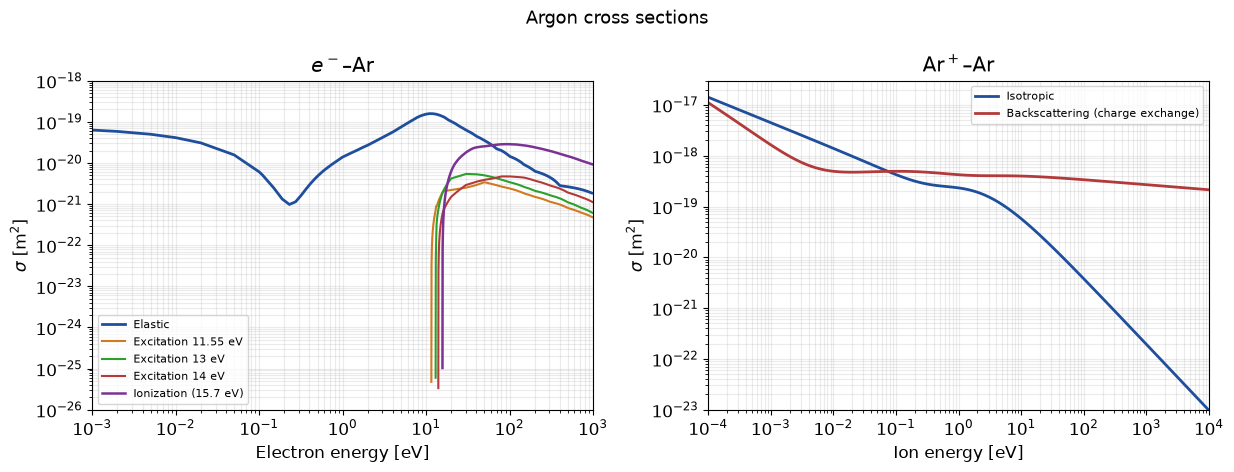

In [15]:
from pathlib import Path

_cross_candidates = [Path("crossSections"), Path("../crossSections")]
CROSS_DIR = next((p for p in _cross_candidates if p.is_dir()), None)
if CROSS_DIR is None:
    raise FileNotFoundError(
        "Could not find crossSections/. Run the notebook from the repository "
        "root or from the notebooks/ directory."
    )


def load_cross_section(filename):
    data = np.loadtxt(CROSS_DIR / filename)
    return data[:, 0], data[:, 1]


electron_curves = [
    ("Elastic", "Ar_e_ELASTIC_CROSS_SECTION.txt", "#1f4e9c", 2.0),
    (r"Excitation 11.55 eV",
     "Ar_e_EXCITATION_11_55_CROSS_SECTION.txt", "#d17a22", 1.5),
    (r"Excitation 13 eV",
     "Ar_e_EXCITATION_13_CROSS_SECTION.txt", "#2ca02c", 1.5),
    (r"Excitation 14 eV",
     "Ar_e_EXCITATION_14_CROSS_SECTION.txt", "#b23a3a", 1.5),
    (r"Ionization (15.7 eV)",
     "Ar_e_IONIZATION_CROSS_SECTION.txt", "#7b3294", 1.8),
]
ion_curves = [
    ("Isotropic", "Ar_Ar+_ISOTROPIC_CROSS_SECTION.txt", "#1f4e9c", 2.0),
    ("Backscattering (charge exchange)",
     "Ar_Ar+_CHARGE_EXCHANGE_CROSS_SECTION.txt", "#b23a3a", 2.0),
]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
panels = [
    (axes[0], electron_curves, r"$e^-$–Ar", "Electron energy [eV]",
     (1e-3, 1e3), (1e-26, 1e-18)),
    (axes[1], ion_curves, r"Ar$^+$–Ar", "Ion energy [eV]",
     (1e-4, 1e4), (1e-23, 3e-17)),
]
for ax, curves, title, xlabel, xlim, ylim in panels:
    for label, filename, color, lw in curves:
        energy, sigma = load_cross_section(filename)
        mask = (energy > 0) & (sigma > 0)
        ax.loglog(energy[mask], sigma[mask], color=color, lw=lw,
                  label=label)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"$\sigma$ [m$^2$]")
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle("Argon cross sections", fontsize=13)
fig.tight_layout()
plt.show()


---
## 5. Questions

**Exercise 1 — conservation laws and planar motion.**
**(a)** Starting from the equation of motion, derive the energy and angular-momentum
conservation laws in polar coordinates.
**(b)** Using the trajectory panel, check numerically that
$E=\tfrac12\mu(\dot r^2+r^2\dot\theta^2)+U$ and $L=\mu r^2\dot\theta$ stay constant along
the orbit. (You can add a few lines of code to compute them from the plotted trajectory.)
**(c)** Why does the trajectory remain in a plane? What would change if the initial
velocity had a component out of that plane?

**Exercise 2 — radial equation and turning point.**
**(a)** Prove the radial equation
$(\dot r/g)^2+2U/(\mu g^2)+(b/r)^2=1$.
**(b)** Show that the minimum approach distance is the largest root of
$U_{\rm eff}(r_0)=E$.
**(c)** Read $r_0$ from the effective-potential panel for several values of $b$ and compare
it with the marker on the trajectory. What happens for the hard sphere when $b<a$?

**Exercise 3 — angle equation and $\chi=\pi-2\Theta$.**
**(a)** Prove the expression for $d\theta/dr$ given in item 3(a).
**(b)** Explain geometrically why $\chi=\pi-2\Theta$.
**(c)** On the trajectory panel, measure $\Theta$ and $\chi$ for a few impact parameters
and check that $\chi+2\Theta=180^\circ$.
**(d)** What is the sign of $\chi$ for a repulsive potential? And for an attractive one?

**Exercise 4 — hard sphere.**
Prove that for $b<a$
$$\chi=\pi-2\arcsin\!\left(\frac{b}{a}\right),$$
and that $\chi=0$ for $b\geq a$. Compare with the $\chi(b)$ panel. Show that the total
cross section is $\sigma=\pi a^2$.

**Exercise 5 — Rutherford's formula.**
For a repulsive Coulomb potential, prove that
$$b=b_{90}\cot\!\left(\frac{\chi}{2}\right),
\qquad b_{90}=\frac{k}{\mu g^2},$$
or equivalently $\chi=2\arctan(b_{90}/b)$. Verify the formula with the H$^+$–H$^+$ curve.
What is $\chi$ at $b=b_{90}$? Discuss the limit $\chi\to0$ as $b\to\infty$ and explain why
the total cross section diverges for a pure Coulomb potential.

**Exercise 6 — inverse power law and the hard-sphere limit.**
Explore $n=1,\ldots,6$ with the slider. How does $\chi(b)$ change with $n$? Show
numerically that for large $n$ the curve approaches the hard-sphere result (with a
suitable definition of the hard-sphere radius). Compare the repulsive and attractive
cases, and explain the capture/orbiting behaviour found for attractive potentials with
$n>1$.

**Exercise 7 — scaling with $g$, $\mu$ and $k$.**
Use the pair and speed controls. How do $b_{90}$, $r_0$ and the normalized curve
$\chi(b/\ell)$ change with $g$, $\mu$ and $k$? Show that for $n=1$ the normalized curve
depends only on $b/b_{90}$. Use the fixed-$b$ panel to show that $\chi$ does change with
$g$ when $b$ is held fixed, even though $\chi(b/\ell)$ does not. What happens for a
neutral pair ($k=0$)?

**Exercise 8 (optional) — Rutherford cross section.**
From $b(\chi)$, derive
$$\frac{d\sigma}{d\Omega}
=\left(\frac{b_{90}}{2}\right)^2\frac{1}{\sin^4(\chi/2)}.$$
Compute the fraction of particles scattered into a given angular range. Why is the total
cross section infinite for the pure Coulomb potential?
